# Baseline analysis: University dropout and school course failure

**Research project:** Fair sequential allocation of limited mentoring/support for school dropout prevention  
### What this notebook estimates

| Experiment | Cohort | What is predicted | What it is **not** |
|---|---|---|---|
| A: University three-class | 4,424 university records | `Dropout` / `Enrolled` / `Graduate` | Permanent dropout among schoolchildren |
| B: University resolved-case | University records with a resolved `Dropout` or `Graduate` label | Dropout vs graduation | All-student dropout probability: `Enrolled` cases are excluded |
| C: Portuguese school | 649 historical Portuguese course anchors | Final course failure (`G3 < 10`) | Actual school dropout |
| D: Synthetic diagnostic | 2,000 generated profiles with hidden assumed parameters | Check simulated hazard/draw consistency **without ML training** | Evidence that any mentor intervention works |

We fit a **majority/prior baseline**, **logistic regression**, **random forest**, **histogram gradient boosting**, and a **PyTorch feed-forward neural network**. All model preprocessing is trained on **training data only**. Existing train/validation/test splits are preserved. The chosen model is selected on the validation set, and its final result is reported on held-out test data.

**Important limitations:** (1) The school dataset has **no observed school-dropout labels**. (2) The university features are a conservative enrollment-time approximation; actual availability timestamps have not been proven for every questionnaire field. (3) Observational classification **does not identify causal intervention effects**. (4) External validity is limited to each source population.

## Setup

In [ ]:
from pathlib import Path
from io import BytesIO
import os, sys, json, random, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             average_precision_score, roc_auc_score, brier_score_loss,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             log_loss, classification_report)
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(2, torch.get_num_threads()))

project_root = Path.cwd()
while project_root != project_root.parent and not (project_root / "data" / "external").is_dir():
    project_root = project_root.parent

OUTPUT_DIR = Path(project_root / 'outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

## Verify and document the available data

A row is not necessarily a unique real person: subject-level Portuguese and Mathematics files overlap; synthetic student rows are bootstrap descendants of existing school profiles. The higher-education population is entirely separate. Missingness in some school socioeconomic fields is intentional/structural, not a reason to impute verified poverty.

In [27]:
files = {
    'school_students': project_root / 'data' / 'processed' / 'students' / 'student_dataset.csv',
    'school_splits': project_root / 'data' / 'processed' / 'splits' / 'split_manifest.csv',
    'school_outcomes': project_root / 'data' / 'external' / 'student_outcomes_reference.csv',
    'subject_records': project_root / 'data' / 'external' / 'subject_records_reference.csv',
    'university_features': project_root / 'data' / 'external' / 'higher_ed_enrollment_features.csv',
    'university_outcomes': project_root / 'data' / 'external' / 'higher_ed_outcomes_reference.csv',
    'synthetic_students': project_root / 'data' / 'synthetic' / 'populations' / 'synthetic_student_population.csv',
    'synthetic_hidden': project_root / 'data' / 'synthetic' / 'simulator_states' / 'simulator_hidden_truth.csv',
    'field_dictionary': project_root / 'data' / 'external' / 'variable_dictionary.csv',
}
def read_csv(path):
    return pd.read_csv(path, low_memory=False)

datasets = {name: read_csv(path) for name, path in files.items()}
summary = pd.DataFrame([
    {'dataset': k, 'rows': len(v), 'columns': len(v.columns),
     'missing_cells': int(v.isna().sum().sum())}
    for k,v in datasets.items()
]).set_index('dataset')
display(summary)
assert len(datasets['school_students']) == 674
assert len(datasets['university_features']) == 4424
assert len(datasets['synthetic_students']) == len(datasets['synthetic_hidden']) == 2000
assert datasets['school_students']['observed_school_dropout'].isna().all(), 'School target definition changed: re-audit before training.'

,rows,columns,missing_cells
dataset,,,
school_students,674,44,2987
school_splits,674,4,0
school_outcomes,674,10,1622
subject_records,1044,39,0
university_features,4424,27,0
university_outcomes,4424,14,0
synthetic_students,2000,51,10915
synthetic_hidden,2000,7,0
field_dictionary,44,8,20


## Construct leakage-aware modelling tables

**University enrollment landmark:** use only the separate `higher_ed_enrollment_features.csv` table. `higher_ed_outcomes_reference.csv` contributes the label `Target` **only**. In particular, **do not** feed 1st/2nd semester credits, approvals, evaluation counts or grades from the outcome table into enrollment-time models. We also exclude `Debtor`, `Tuition fees up to date`, and `Scholarship holder` in the strict baseline because their measurement times are uncertain. `Gender`, `Nacionality`, and `Educational special needs` are reserved for auditing rather than default model input.

**School first-period landmark:** use original contextual variables + `anchor_grade1_0_20` after G1 becomes known. The historical label is `anchor_course_failure_proxy` (G3 < 10) from a separate outcome table. Do not use G2, final G3, final absences, linked Mathematics G1 without proven timing, synthetic learning gap, IDs, or proxies derived from future data as features.

For school we restrict the primary task to the **649 Portuguese anchors** so the target has a consistent course meaning. The other 25 mathematics-only anchors can be evaluated in a separately declared sensitivity experiment, not silently pooled.

In [28]:
univ_f = datasets['university_features']
univ_o = datasets['university_outcomes']
assert univ_f['record_id'].is_unique and univ_o['record_id'].is_unique
university = univ_f.merge(univ_o[['record_id','Target']], on='record_id', validate='one_to_one')
assert len(university) == 4424
assert university['Target'].isin(['Dropout','Enrolled','Graduate']).all()

school_f = datasets['school_students']
school_o = datasets['school_outcomes']
school_split = datasets['school_splits']
assert school_f['student_id'].is_unique and school_o['student_id'].is_unique and school_split['student_id'].is_unique
school = school_f.merge(
    school_o[['student_id','anchor_course_failure_proxy','anchor_final_grade_0_20']],
    on='student_id', validate='one_to_one'
)
school = school.merge(
    school_split[['student_id','linkage_group_id','split']], on='student_id',
    validate='one_to_one', suffixes=('','_manifest')
)
assert (school['split'] == school['split_manifest']).all()
assert (school['linkage_group_id'] == school['linkage_group_id_manifest']).all()
assert (school['anchor_course_failure_proxy'] == (school['anchor_final_grade_0_20'] < 10).astype(int)).all()
portuguese = school.loc[school['anchor_subject'].eq('portuguese')].copy()
assert len(portuguese) == 649

for name, df in [('university',university), ('Portuguese school',portuguese)]:
    assert df['split'].isin(['train','validation','test']).all()
    group_sets = [set(df.loc[df.split.eq(s), 'linkage_group_id']) for s in ['train','validation','test']]
    assert not group_sets[0].intersection(group_sets[1])
    assert not group_sets[0].intersection(group_sets[2])
    assert not group_sets[1].intersection(group_sets[2])
    print(name, 'split counts:', df['split'].value_counts().to_dict(), '; linkage overlap: none')

print('University Target:', university['Target'].value_counts().to_dict())
print('Portuguese course failure:', portuguese['anchor_course_failure_proxy'].value_counts().to_dict())

university split counts: {'train': 2658, 'test': 908, 'validation': 858} ; linkage overlap: none
Portuguese school split counts: {'train': 388, 'test': 136, 'validation': 125} ; linkage overlap: none
University Target: {'Graduate': 2209, 'Dropout': 1421, 'Enrolled': 794}
Portuguese course failure: {0: 549, 1: 100}


### Freeze explicitly permitted features

University coded category variables are one-hot encoded: their numeric codes are **not continuous quantities**. All preprocessing, including imputation and scaling, is fitted to training cases only. The feature list is intentionally conservative and auditable; adapt it only after documenting a prediction time point.

In [29]:
UNIV_CATEGORICAL = [
    'Marital status', 'Application mode', 'Course', 'Daytime/evening attendance',
    'Previous qualification', "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation", 'Displaced', 'International',
]
UNIV_NUMERIC = [
    'Age at enrollment', 'Application order', 'Previous qualification (grade)',
    'Admission grade', 'Unemployment rate', 'Inflation rate', 'GDP',
]
UNIV_AUDIT_ONLY = ['Gender', 'Nacionality', 'Educational special needs']
UNIV_UNKNOWN_TIMING = ['Debtor', 'Tuition fees up to date', 'Scholarship holder']

SCHOOL_CATEGORICAL = [
    'school_id', 'rural_residence', 'family_size_gt3', 'parents_apart',
    'mother_education_code', 'father_education_code', 'mother_job','father_job',
    'guardian', 'travel_time_category', 'study_time_category',
    'school_support_existing', 'family_support_existing', 'paid_classes_existing',
    'extracurricular', 'nursery_attended', 'higher_education_aspiration', 'internet_at_home',
    'family_relationship_rating', 'health_self_rating',
]
SCHOOL_NUMERIC = ['age_years','past_failures_count','anchor_grade1_0_20']
SCHOOL_AUDIT_ONLY = ['sex_source','disadvantage_proxy_group']

for f in UNIV_CATEGORICAL+UNIV_NUMERIC+UNIV_AUDIT_ONLY+UNIV_UNKNOWN_TIMING:
    assert f in university.columns, f
for f in SCHOOL_CATEGORICAL+SCHOOL_NUMERIC+SCHOOL_AUDIT_ONLY:
    assert f in portuguese.columns, f
assert not set(UNIV_CATEGORICAL+UNIV_NUMERIC) & set(UNIV_AUDIT_ONLY+UNIV_UNKNOWN_TIMING)
assert not set(SCHOOL_CATEGORICAL+SCHOOL_NUMERIC) & set(SCHOOL_AUDIT_ONLY)
assert not any('grade2' in f or 'final' in f or 'dropout' in f.lower() for f in SCHOOL_CATEGORICAL+SCHOOL_NUMERIC)

print('University enrollment features:', len(UNIV_CATEGORICAL+UNIV_NUMERIC))
print('Portuguese first-period features:', len(SCHOOL_CATEGORICAL+SCHOOL_NUMERIC))
print('Excluded university unclear-time financial attributes:', UNIV_UNKNOWN_TIMING)

University enrollment features: 18
Portuguese first-period features: 23
Excluded university unclear-time financial attributes: ['Debtor', 'Tuition fees up to date', 'Scholarship holder']


## Common training and evaluation functions

All experiments use the same original train/validation/test split. Performance includes class-sensitive scores and **dropout/failure one-vs-rest PR-AUC** (important for imbalanced outcomes), plus ROC-AUC, Brier score and top-10%-review recall. Since test sets are modest, apparent differences should not be overinterpreted.

The neural network has two hidden layers (64 and 32 units), ReLU activation, dropout regularization, and cross-entropy loss, with **validation-loss early stopping**. It is a predictive model, **not** a simulator of mentor effects.

In [30]:
def make_preprocessor(categorical, numeric):
    return ColumnTransformer([
        ('category', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical),
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), numeric),
    ], remainder='drop', sparse_threshold=0)

class TabularMLP(nn.Module):
    def __init__(self, in_features, n_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 64), nn.ReLU(), nn.Dropout(0.20),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.15),
            nn.Linear(32, n_classes),
        )
    def forward(self, x):
        return self.net(x)

def fit_neural_net(x_tr, y_tr, x_val, y_val, n_classes, *, max_epochs=90, patience=12):
    torch.manual_seed(SEED)
    model = TabularMLP(x_tr.shape[1], n_classes).to('cpu')
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.0015, weight_decay=0.01)
    loss_fn = nn.CrossEntropyLoss()
    xtr_t = torch.tensor(x_tr, dtype=torch.float32)
    ytr_t = torch.tensor(y_tr, dtype=torch.long)
    xv_t = torch.tensor(x_val, dtype=torch.float32)
    yv_t = torch.tensor(y_val, dtype=torch.long)
    loader = DataLoader(TensorDataset(xtr_t, ytr_t), batch_size=128, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    best_loss = float('inf')
    best_weights = None
    best_epoch = 0
    history = []
    for epoch in range(1, max_epochs + 1):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            current_loss = float(loss_fn(model(xv_t), yv_t))
        history.append(current_loss)
        if current_loss < best_loss - 1e-4:
            best_loss = current_loss
            best_epoch = epoch
            best_weights = {k: v.detach().clone() for k,v in model.state_dict().items()}
        if epoch - best_epoch >= patience:
            break
    model.load_state_dict(best_weights)
    model.eval()
    return model, history, best_epoch

def nn_proba(model, x):
    with torch.no_grad():
        return torch.softmax(model(torch.tensor(x, dtype=torch.float32)), dim=1).numpy()

def scores(y_true, probabilities, *, positive_id=0):
    # First class (0) denotes Dropout or Failure in all experiments.
    predicted = probabilities.argmax(axis=1)
    binary_truth = (np.asarray(y_true) == positive_id).astype(int)
    positive_prob = probabilities[:, positive_id]
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, predicted, labels=np.arange(probabilities.shape[1]),
        average='macro', zero_division=0)
    cls_p, cls_r, cls_f1, _ = precision_recall_fscore_support(
        binary_truth, (predicted==positive_id).astype(int), average='binary', zero_division=0)
    n_review = max(1, int(np.ceil(0.10 * len(y_true))))
    selected = np.argsort(-positive_prob)[:n_review]
    top_recall = float(binary_truth[selected].sum()/max(1,binary_truth.sum()))
    return {
        'accuracy': accuracy_score(y_true,predicted),
        'balanced_accuracy': balanced_accuracy_score(y_true,predicted),
        'macro_precision': p, 'macro_recall': r, 'macro_f1': f1,
        'positive_precision': cls_p, 'positive_recall': cls_r, 'positive_f1': cls_f1,
        'positive_pr_auc': average_precision_score(binary_truth,positive_prob),
        'positive_roc_auc': roc_auc_score(binary_truth,positive_prob) if np.unique(binary_truth).size==2 else np.nan,
        'positive_brier': brier_score_loss(binary_truth,positive_prob),
        'recall_at_top_10pct': top_recall,
        'log_loss': log_loss(y_true,probabilities,labels=np.arange(probabilities.shape[1])),
    }

def model_factories():
    return {
        'Prior / majority': DummyClassifier(strategy='prior'),
        'Logistic regression': LogisticRegression(max_iter=1600, random_state=SEED),
        'Random forest': RandomForestClassifier(n_estimators=180, min_samples_leaf=3,
                                                 n_jobs=-1, random_state=SEED),
        'Gradient boosting': HistGradientBoostingClassifier(max_iter=130,
                                max_leaf_nodes=13, min_samples_leaf=12,
                                learning_rate=0.07, l2_regularization=0.1,
                                random_state=SEED),
    }

### Fixed train/validation/test runner

**Model selection:** choose the model with the best validation **positive-class PR-AUC**; ties are broken by lower validation Brier score. The held-out test predictions are then reported. The same test set is shown for all models for transparency, but it must **not** be used to tune model selection or hyperparameters.

In [31]:
def run_experiment(df, categorical, numeric, label_col, label_order, name):
    features = categorical + numeric
    assert len(set(features)) == len(features)
    assert set(features).issubset(df.columns)
    class_to_id = {c:i for i,c in enumerate(label_order)}
    allowed = df.loc[df[label_col].isin(label_order)].copy()
    allowed['_encoded_label'] = allowed[label_col].map(class_to_id).astype(int)

    parts = {split: allowed.loc[allowed['split'].eq(split)].copy()
             for split in ['train','validation','test']}
    for split in parts:
        assert parts[split]['_encoded_label'].nunique() == len(label_order),             f'{name}: {split} missing a target class; re-evaluate metric definitions.'
    transformer = make_preprocessor(categorical,numeric)
    x = {k: np.asarray(transformer.fit_transform(v[features]) if k == 'train'
                      else transformer.transform(v[features]), dtype=np.float32)
         for k,v in parts.items()}
    y = {k: v['_encoded_label'].to_numpy() for k,v in parts.items()}
    assert all(np.isfinite(v).all() for v in x.values())
    assert len(parts['train'])+len(parts['validation'])+len(parts['test']) == len(allowed)

    models = model_factories()
    predictions = {}
    histories = {}
    for model_name, model in models.items():
        model.fit(x['train'], y['train'])
        predictions[model_name] = {}
        for split in ['validation','test']:
            proba = model.predict_proba(x[split])
            assert np.array_equal(model.classes_, np.arange(len(label_order)))
            predictions[model_name][split] = proba
        models[model_name] = model
    net, history, best_epoch = fit_neural_net(
        x['train'], y['train'], x['validation'], y['validation'], len(label_order))
    models['Neural network (PyTorch)'] = net
    predictions['Neural network (PyTorch)'] = {
        split: nn_proba(net,x[split]) for split in ['validation','test']
    }
    histories['nn_val_loss'] = history
    histories['nn_best_epoch'] = best_epoch

    score_rows = []
    for model_name, split_probs in predictions.items():
        for split in ['validation','test']:
            score_rows.append({
                'model': model_name, 'split': split,
                **scores(y[split],split_probs[split]),
            })
    report = pd.DataFrame(score_rows)
    val = report.loc[report['split'].eq('validation')].sort_values(
        ['positive_pr_auc','positive_brier'],ascending=[False,True])
    winner = str(val.iloc[0]['model'])
    print(f'\n{name} | sample sizes: ' + str({k:len(v) for k,v in parts.items()}))
    print('Class labels:',label_order)
    print('Winner selected by validation PR-AUC:',winner)
    cols = ['model','split','positive_pr_auc','positive_roc_auc','positive_recall',
            'macro_f1','positive_brier','recall_at_top_10pct']
    display(report[cols].round(3))
    safe_name = name.lower().replace(' ','_').replace('/','_')
    report.to_csv(OUTPUT_DIR / f'{safe_name}_metrics.csv', index=False)
    return {'name':name,'labels':label_order,'parts':parts,'x':x,'y':y,
            'preprocessor':transformer,'models':models,'predictions':predictions,
            'report':report,'winner':winner,'history':histories}

all_experiments = {}

## Experiment A — Real higher-education three-class status prediction

We retain `Enrolled` explicitly instead of forcing unresolved cases to be negative outcomes. `Dropout` is the positive class for PR-AUC/ROC-AUC and top-k prioritization. The predicted probabilities estimate outcome **under the source data and its observed support context**, not an untreated causal counterfactual.

In [32]:
university_3class = run_experiment(
    university, UNIV_CATEGORICAL, UNIV_NUMERIC, 'Target',
    ['Dropout','Enrolled','Graduate'], 'university_three_class'
)
all_experiments['university_three_class'] = university_3class

/var/folders/wp/gc0pmmnx4d91zc8_lsf9s99h0000gn/T/ipykernel_58151/1165050162.py:7: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  allowed['_encoded_label'] = allowed[label_col].map(class_to_id).astype(int)



university_three_class | sample sizes: {'train': 2658, 'validation': 858, 'test': 908}
Class labels: ['Dropout', 'Enrolled', 'Graduate']
Winner selected by validation PR-AUC: Random forest


,model,split,positive_pr_auc,positive_roc_auc,positive_recall,macro_f1,positive_brier,recall_at_top_10pct
0,Prior / majority,validation,0.319,0.500,0.000,0.221,0.217,0.084
1,Prior / majority,test,0.317,0.500,0.000,0.223,0.217,0.094
2,Logistic regression,validation,0.579,0.731,0.496,0.477,0.185,0.223
3,Logistic regression,test,0.614,0.753,0.503,0.491,0.176,0.243
4,Random forest,validation,0.603,0.736,0.478,0.411,0.184,0.248
5,Random forest,test,0.606,0.770,0.490,0.411,0.178,0.208
6,Gradient boosting,validation,0.573,0.730,0.496,0.472,0.186,0.223
7,Gradient boosting,test,0.605,0.759,0.538,0.512,0.176,0.226
8,Neural network (PyTorch),validation,0.584,0.737,0.602,0.429,0.184,0.223
9,Neural network (PyTorch),test,0.614,0.767,0.597,0.431,0.174,0.236


## Experiment B — Binary university dropout among resolved cases

For a familiar binary dropout classifier, exclude `Enrolled` cases and compare only `Dropout` vs `Graduate`. This **changes the estimate**: the probability is conditional on having a resolved outcome. Do not apply it unquestioningly as an unconditional risk to all enrolled university students.

In [33]:
resolved = university.loc[university['Target'].isin(['Dropout','Graduate'])].copy()
print('Excluded unresolved Enrolled cases:',len(university)-len(resolved))
print('Resolved-case target distribution:',resolved['Target'].value_counts().to_dict())
university_resolved = run_experiment(
    resolved,UNIV_CATEGORICAL,UNIV_NUMERIC,'Target',
    ['Dropout','Graduate'],'university_resolved_binary'
)
all_experiments['university_resolved_binary'] = university_resolved

Excluded unresolved Enrolled cases: 794
Resolved-case target distribution: {'Graduate': 2209, 'Dropout': 1421}


/var/folders/wp/gc0pmmnx4d91zc8_lsf9s99h0000gn/T/ipykernel_58151/1165050162.py:7: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  allowed['_encoded_label'] = allowed[label_col].map(class_to_id).astype(int)



university_resolved_binary | sample sizes: {'train': 2186, 'validation': 700, 'test': 744}
Class labels: ['Dropout', 'Graduate']
Winner selected by validation PR-AUC: Random forest


,model,split,positive_pr_auc,positive_roc_auc,positive_recall,macro_f1,positive_brier,recall_at_top_10pct
0,Prior / majority,validation,0.391,0.500,0.000,0.378,0.238,0.102
1,Prior / majority,test,0.387,0.500,0.000,0.380,0.237,0.094
2,Logistic regression,validation,0.672,0.757,0.522,0.691,0.192,0.204
3,Logistic regression,test,0.697,0.780,0.490,0.685,0.184,0.205
4,Random forest,validation,0.692,0.774,0.526,0.697,0.188,0.219
5,Random forest,test,0.717,0.795,0.514,0.690,0.182,0.219
6,Gradient boosting,validation,0.671,0.757,0.515,0.675,0.191,0.219
7,Gradient boosting,test,0.731,0.802,0.583,0.734,0.172,0.212
8,Neural network (PyTorch),validation,0.666,0.756,0.566,0.683,0.193,0.201
9,Neural network (PyTorch),test,0.685,0.778,0.545,0.689,0.185,0.205


## Experiment C — Portuguese-school course failure (NOT actual dropout)

Here the label is `anchor_course_failure_proxy = 1` if final grade G3 < 10. This is the school's **only supported historical classification target** in these files. We convert it to names `Failure`/`Pass` to make the positive class unambiguous. Unlike the university outcome, this is **not a dropout prediction experiment**.

In [34]:
portuguese = portuguese.copy()
portuguese['course_result'] = portuguese['anchor_course_failure_proxy'].map({1:'Failure',0:'Pass'})
school_failure = run_experiment(
    portuguese,SCHOOL_CATEGORICAL,SCHOOL_NUMERIC,'course_result',
    ['Failure','Pass'],'portuguese_course_failure'
)
all_experiments['portuguese_course_failure'] = school_failure

/var/folders/wp/gc0pmmnx4d91zc8_lsf9s99h0000gn/T/ipykernel_58151/2258107261.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  portuguese['course_result'] = portuguese['anchor_course_failure_proxy'].map({1:'Failure',0:'Pass'})
/var/folders/


portuguese_course_failure | sample sizes: {'train': 388, 'validation': 125, 'test': 136}
Class labels: ['Failure', 'Pass']
Winner selected by validation PR-AUC: Gradient boosting


,model,split,positive_pr_auc,positive_roc_auc,positive_recall,macro_f1,positive_brier,recall_at_top_10pct
0,Prior / majority,validation,0.096,0.500,0.000,0.475,0.092,0.167
1,Prior / majority,test,0.162,0.500,0.000,0.456,0.136,0.045
2,Logistic regression,validation,0.404,0.893,0.500,0.689,0.090,0.417
3,Logistic regression,test,0.790,0.931,0.682,0.831,0.072,0.591
4,Random forest,validation,0.456,0.895,0.250,0.630,0.072,0.417
5,Random forest,test,0.727,0.923,0.409,0.741,0.077,0.500
6,Gradient boosting,validation,0.459,0.905,0.667,0.724,0.096,0.417
7,Gradient boosting,test,0.773,0.943,0.682,0.831,0.070,0.455
8,Neural network (PyTorch),validation,0.308,0.839,0.083,0.539,0.078,0.333
9,Neural network (PyTorch),test,0.590,0.896,0.273,0.663,0.093,0.364


## Inspect held-out confusion matrix, PR curve, calibration and training history

Each visualization is for the **validation-selected** model on the untouched test split. PR-AUC is informative for rare failures/dropouts; calibration indicates whether numerical risks are trustworthy. Neither confirms a causal intervention effect.


university_three_class: selected = Random forest
              precision    recall  f1-score   support

     Dropout       0.58      0.49      0.53       288
    Enrolled       0.00      0.00      0.00       164
    Graduate       0.59      0.86      0.70       456

    accuracy                           0.59       908
   macro avg       0.39      0.45      0.41       908
weighted avg       0.48      0.59      0.52       908



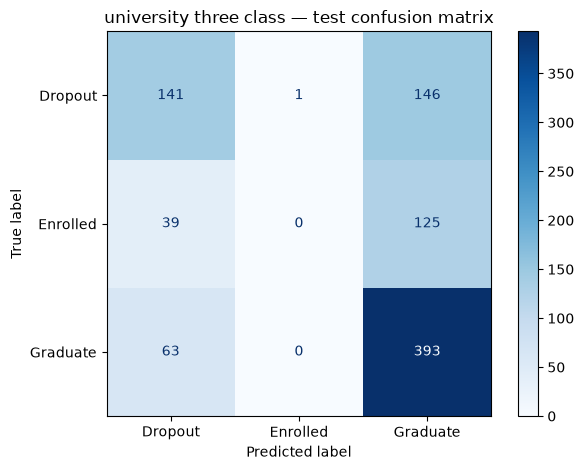

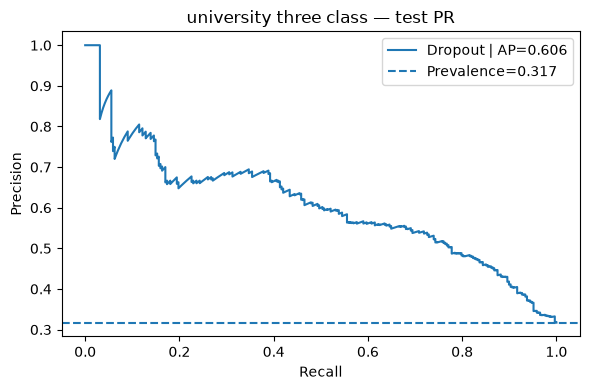

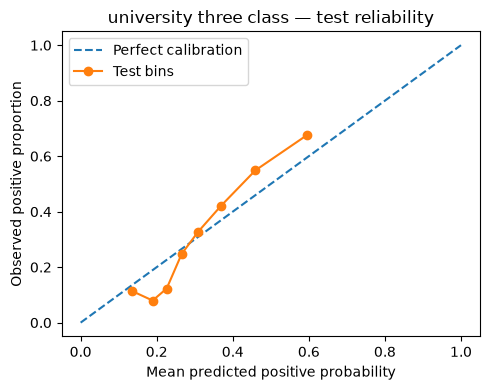


university_resolved_binary: selected = Random forest
              precision    recall  f1-score   support

     Dropout       0.69      0.51      0.59       288
    Graduate       0.74      0.86      0.79       456

    accuracy                           0.72       744
   macro avg       0.71      0.68      0.69       744
weighted avg       0.72      0.72      0.71       744



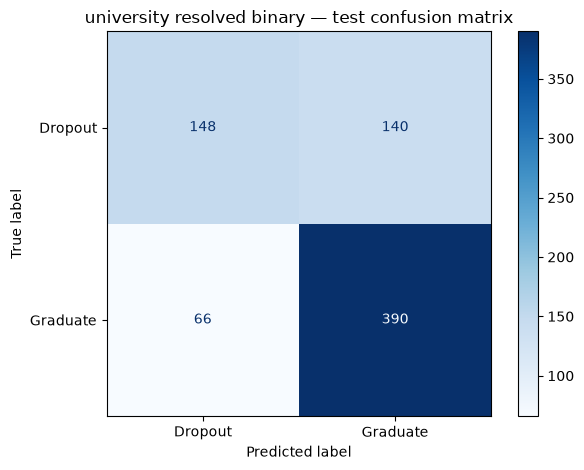

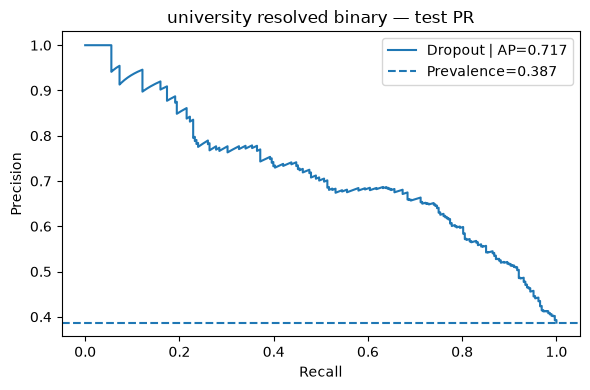

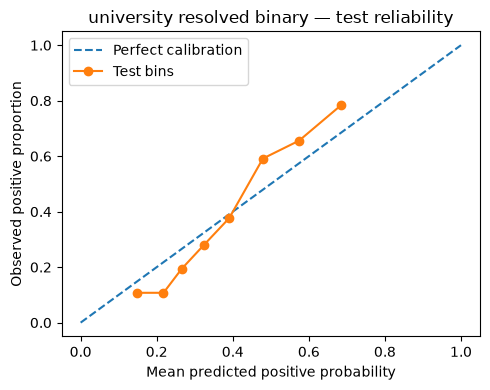


portuguese_course_failure: selected = Gradient boosting
              precision    recall  f1-score   support

     Failure       0.75      0.68      0.71        22
        Pass       0.94      0.96      0.95       114

    accuracy                           0.91       136
   macro avg       0.84      0.82      0.83       136
weighted avg       0.91      0.91      0.91       136



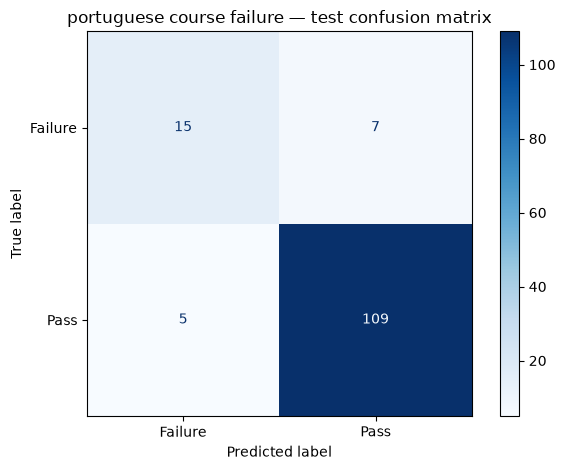

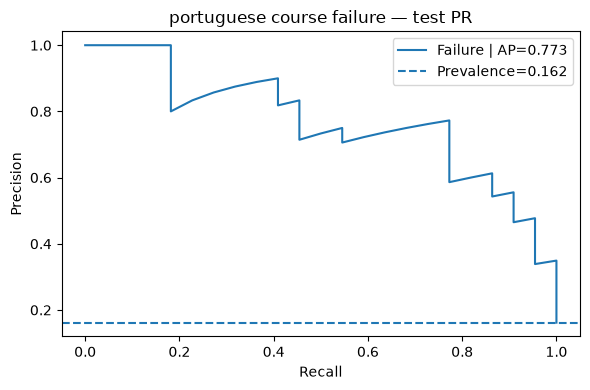

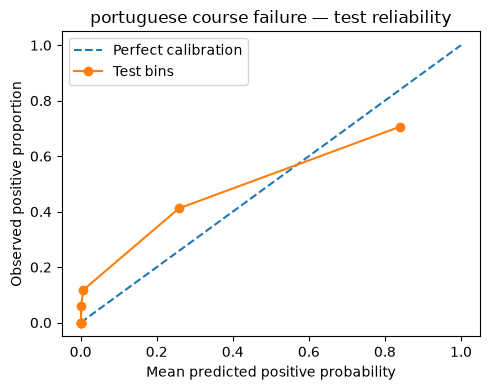

In [35]:
def visualize_experiment(exp):
    name = exp['name']
    w = exp['winner']
    actual = exp['y']['test']
    proba = exp['predictions'][w]['test']
    predicted = proba.argmax(axis=1)
    print(f'\n{name}: selected = {w}')
    print(classification_report(actual,predicted,labels=list(range(len(exp['labels']))),
                                target_names=exp['labels'],zero_division=0))
    ConfusionMatrixDisplay.from_predictions(actual,predicted,labels=list(range(len(exp['labels']))),
                                            display_labels=exp['labels'],cmap='Blues',values_format='d')
    plt.title(name.replace('_',' ') + ' — test confusion matrix')
    plt.tight_layout(); plt.show()

    positive = (actual==0).astype(int)
    from sklearn.metrics import precision_recall_curve
    precision, recall, _ = precision_recall_curve(positive,proba[:,0])
    plt.figure(figsize=(6,4))
    plt.plot(recall,precision,label=f'{exp["labels"][0]} | AP={average_precision_score(positive,proba[:,0]):.3f}')
    plt.axhline(positive.mean(),linestyle='--',label=f'Prevalence={positive.mean():.3f}')
    plt.xlabel('Recall');plt.ylabel('Precision');plt.title(name.replace('_',' ') + ' — test PR')
    plt.legend();plt.tight_layout();plt.show()

    # Equal-frequency bins; small groups may have imprecise reliability estimates.
    bins = pd.qcut(pd.Series(proba[:,0]).rank(method='first'),q=8,labels=False)
    reliability = pd.DataFrame({'bin':bins,'risk':proba[:,0],'actual':positive}).groupby('bin',as_index=False).agg(
        mean_risk=('risk','mean'), observed_rate=('actual','mean'),count=('actual','size'))
    plt.figure(figsize=(5,4))
    plt.plot([0,1],[0,1],linestyle='--',label='Perfect calibration')
    plt.plot(reliability.mean_risk,reliability.observed_rate,marker='o',label='Test bins')
    plt.xlabel('Mean predicted positive probability');plt.ylabel('Observed positive proportion')
    plt.title(name.replace('_',' ')+' — test reliability');plt.legend();plt.tight_layout();plt.show()

for experiment in all_experiments.values():
    visualize_experiment(experiment)

### Neural network learning curves

These curves measure external validation cross-entropy over epochs. They are not learning trajectories of student agents.

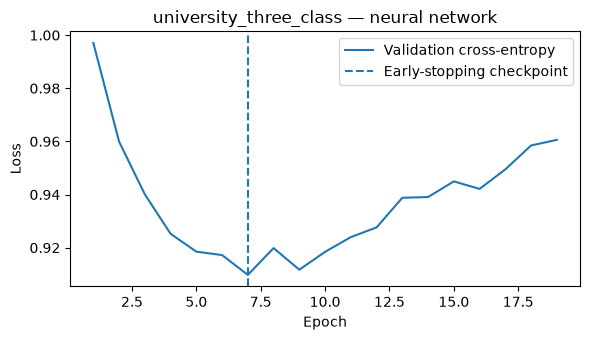

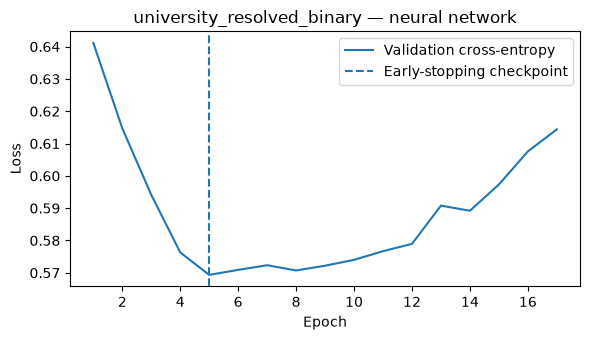

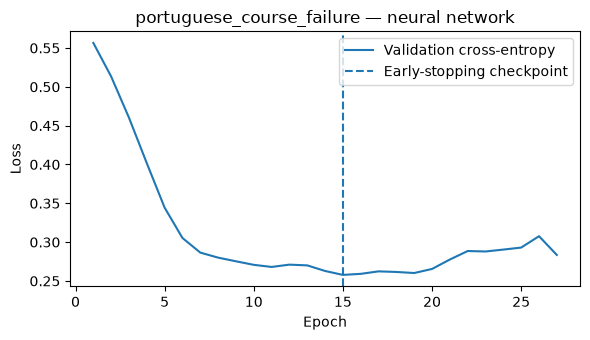

In [36]:
for exp in all_experiments.values():
    h = exp['history']['nn_val_loss']
    plt.figure(figsize=(6,3.5))
    plt.plot(range(1,len(h)+1),h,label='Validation cross-entropy')
    plt.axvline(exp['history']['nn_best_epoch'],linestyle='--',label='Early-stopping checkpoint')
    plt.title(exp['name']+' — neural network')
    plt.xlabel('Epoch');plt.ylabel('Loss');plt.legend();plt.tight_layout();plt.show()

## Subgroup inspection (descriptive, not a fairness guarantee)

We calculate test-set dropout/failure **ranking selection rate**, observed prevalence and PR-AUC by existing audit groups. We use the audit variables only for evaluation, not for default model fitting. At 10% overall review capacity, different groups may receive different fractions of flags. Small cells can make subgroup PR-AUC unreliable. Neither equal selection rates nor unequal ones, by themselves, determine normative fairness: compare eligible students of comparable need in the later allocation experiments.

In [37]:
def subgroup_table(exp, field):
    frame = exp['parts']['test'].reset_index(drop=True)
    prob = exp['predictions'][exp['winner']]['test'][:,0]
    y = exp['y']['test']
    n_review = max(1,int(np.ceil(.10*len(y))))
    chosen = np.zeros(len(y),dtype=int)
    chosen[np.argsort(-prob)[:n_review]] = 1
    d = pd.DataFrame({'group':frame[field].astype('string').fillna('Unknown'),
                      'positive':(y==0).astype(int),'score':prob,'flag':chosen})
    rows=[]
    for group,g in d.groupby('group',dropna=False):
        rows.append({'group':str(group),'n':len(g),'positive_n':int(g.positive.sum()),
                     'observed_positive_fraction':g.positive.mean(),
                     'top10_flag_rate':g.flag.mean(),
                     'PR_AUC':average_precision_score(g.positive,g.score) if g.positive.nunique()==2 else np.nan})
    return pd.DataFrame(rows)

print('University test — audit by gender code (definitions from source codebook):')
display(subgroup_table(university_3class,'Gender').round(3))
print('Portuguese test — disadvantage proxy group (not verified poverty):')
display(subgroup_table(school_failure,'disadvantage_proxy_group').round(3))

University test — audit by gender code (definitions from source codebook):


,group,n,positive_n,observed_positive_fraction,top10_flag_rate,PR_AUC
0,0,593,151,0.255,0.078,0.518
1,1,315,137,0.435,0.143,0.701


Portuguese test — disadvantage proxy group (not verified poverty):


,group,n,positive_n,observed_positive_fraction,top10_flag_rate,PR_AUC
0,0,112,17,0.152,0.080,0.864
1,1,24,5,0.208,0.208,0.516


## Experiment D — Synthetic assumed-hazard sanity check ONLY

The synthetic population is derived from Portuguese school profiles. Its `annual_dropout_probability_assumed` and pre-generated static draw come from an **assumed scenario** and are **not observed school-dropout labels**. This section checks static-hazard consistency only; it does **not fit or test a predictive dropout model**, and this pre-generated draw must not determine outcomes in a sequential mentor-intervention simulator. The environment should instead sample time-dependent transitions from its specified causal-response assumptions.

In [38]:
synthetic = datasets['synthetic_students']
hidden = datasets['synthetic_hidden']
assert synthetic['student_id'].is_unique and hidden['student_id'].is_unique
sim_truth = synthetic[['student_id','source_anchor_student_id','split']].merge(
    hidden, on='student_id', validate='one_to_one')
assert len(sim_truth) == 2000
assert sim_truth['annual_dropout_probability_assumed'].between(0,1).all()
assert sim_truth['constant_weekly_hazard_assumed'].between(0,1).all()
assert sim_truth['dropout_draw_at_static_annual_hazard_assumed'].isin([0,1]).all()
assert set(sim_truth['source_anchor_student_id']).issubset(set(school_f['student_id']))
for source_id, sub in sim_truth.groupby('source_anchor_student_id'):
    assert len(set(sub['split'])) == 1, 'Source bootstrap descendants crossed train/test boundary.'
print('Original school profiles represented:',sim_truth['source_anchor_student_id'].nunique())
print('Simulation-only diagnostic:')
display(sim_truth.groupby('split').agg(
    n=('student_id','size'),
    average_assumed_probability=('annual_dropout_probability_assumed','mean'),
    static_draw_rate=('dropout_draw_at_static_annual_hazard_assumed','mean')
).round(4))
print('NOTE: The simulated static draw rate is neither real dropout prevalence nor an intervention effect.')

Original school profiles represented: 615
Simulation-only diagnostic:


,n,average_assumed_probability,static_draw_rate
split,,,
test,400,0.0972,0.1175
train,1200,0.1005,0.0867
validation,400,0.0985,0.0925


NOTE: The simulated static draw rate is neither real dropout prevalence nor an intervention effect.


## Compact model comparison and researcher interpretation

The table below compares the held-out performance of the **validation-selected** models. A fair comparison of university and school model quality is not possible solely from higher/lower AUC because the labels and source populations differ.

In [39]:
leaderboard=[]
for exp in all_experiments.values():
    row=exp['report'].loc[(exp['report']['model']==exp['winner'])&
                          (exp['report']['split']=='test')].iloc[0]
    leaderboard.append({'task':exp['name'],'selected_model':exp['winner'],
                        'test_n':len(exp['y']['test']),
                        'positive_rate':np.mean(exp['y']['test']==0),
                        'PR_AUC':row['positive_pr_auc'],
                        'ROC_AUC':row['positive_roc_auc'],
                        'positive_recall':row['positive_recall'],
                        'macro_F1':row['macro_f1'],
                        'Brier':row['positive_brier'],
                        'recall_at_10pct':row['recall_at_top_10pct']})
leaderboard=pd.DataFrame(leaderboard)
display(leaderboard.round(3))
leaderboard.to_csv(OUTPUT_DIR/'selected_models_test_summary.csv',index=False)

,task,selected_model,test_n,positive_rate,PR_AUC,ROC_AUC,positive_recall,macro_F1,Brier,recall_at_10pct
0,university_three_class,Random forest,908,0.317,0.606,0.770,0.490,0.411,0.178,0.208
1,university_resolved_binary,Random forest,744,0.387,0.717,0.795,0.514,0.690,0.182,0.219
2,portuguese_course_failure,Gradient boosting,136,0.162,0.773,0.943,0.682,0.831,0.070,0.455


## How to use these baselines in the allocation project

1. **Observed prediction baseline:** the university task measures actual university status prediction; it is a separate external task and its model **must not** directly score schoolchildren.
2. **School academic-risk baseline:** the Portuguese course-failure model can inform a narrowly labelled academic-performance priority baseline, not real school dropout risk or intervention benefit.
3. **Simulated withdrawal-risk baseline:** create the environment and generate longitudinal *training-world* trajectories. Label each landmark by **future withdrawal under a declared support regime and time horizon**. Fit a new risk model on observed/estimated state at that landmark, then freeze it and evaluate on independent held-out scenarios and source anchor groups. This is **not implemented by this notebook**, because the ZIP contains only static reset records, not trajectories.
4. **Fair allocation experiments:** compare usual support, random, waiting-time, risk-priority, and benefit-aware/fair sequential allocation under exactly the same capacity, observation regime and simulation parameters. Risk ranking alone does not establish action benefit.
5. **RAG/QLoRA:** add later if mentor notes exist and information extraction adds a measurable benefit. The language model is not the causal ground truth.

### Threats to validity / report wording

- The university dataset consists of higher-education students; `Enrolled` is unresolved. Conditional binary estimates exclude this group.
- Semester grades and approvals are outcomes/post-landmark variables, not permitted predictors at enrollment time. Some retained enrollment questionnaire fields lack independently verified timestamps; if unavailable at deployment, remove them too.
- The school dataset records **academic course failure, not observed dropout**; source-person links across subjects are uncertain. The model is evaluated on 649 Portuguese anchors with fixed linkage-group splits.
- Synthetic school children inherit bootstrap profiles and artificially generated state. Neither sample size 2,000 nor accuracy in recovering assumed hazard parameters proves real-world generalization.
- Calibration and groupwise access characteristics need external validation. This notebook reports observational classification metrics, **not** causal improvements in school retention.
- Models are fit once on fixed splits; the notebook is a baseline, not a repeated cross-validated estimate or a pre-registered intervention trial. Do not repeatedly inspect the test data while choosing designs.

**Suggested report sentence:** “We established real observational baselines for university dropout status and secondary-school course failure, keeping prediction targets and time-of-availability constraints separate. The supplied school cohort lacks verified dropout labels and intervention histories, so future school-withdrawal and tutoring-effect experiments will be evaluated only within an explicit, versioned semi-synthetic environment.”

---
# PCA dimensionality reduction and feature selection

1. **Original features:** the existing one-hot-encoded and imputed features above; this is the reference baseline.
2. **PCA component features:** standardized encoded features → train-fitted PCA, retaining at least **95%** of training-set variance → train the models, including the PyTorch neural network.
3. **PCA-ranked original features:** use the **first 10 principal components** from the train-fitted PCA to rank *source columns* (aggregating categories); retain the top **60%** of original variables, then refit a fresh train-only preprocessor and models, including the neural network.

**Important interpretation:** Principal components are linear combinations of encoded variables, not named original features. Large PCA loadings and variance contributions indicate *representation of variation*, **not predictive importance or causality**. A PCA-selected original-variable experiment is included for interpretability, but it is an unsupervised ranking and can lose target-related information. Feature ranking, standardization, PCA, missing-value imputation, and neural-network fitting use **training data only**. The validation partition selects each representation's winning model; the test partition measures generalization.

Neither PCA nor a higher predictive score transforms Portuguese **course failure** into observed school dropout or establishes intervention effectiveness. `Enrolled` remains a distinct university class in the three-class task. All split/target/feature-exclusion rules defined earlier are retained.

## Fit PCA on the *training* matrix and examine explained variance

The original `ColumnTransformer` produces dummy/one-hot variables for categorical fields and standardized numerical fields. Since their scales can differ, the PCA experiment adds a **second train-only `StandardScaler`** across the encoded feature columns. This gives each encoded column unit variance where possible; infrequent one-hot categories can therefore receive substantial weight. Zero-variance encoded columns remain zero after scaling. The transformation is transparent and consistent across train/validation/test.

The 95% threshold, first-10-PC ranking rule, and 60% original-field retention fraction are fixed **before viewing test results**. They are descriptive design settings, not data-driven optima.

In [40]:
from sklearn.decomposition import PCA

PCA_VARIANCE_TARGET = 0.95
PCA_ORIGINAL_FIELD_FRACTION = 0.60
PCA_RANKING_COMPONENTS = 10  # Focus the unsupervised ranking on dominant variance axes.

# Only original supervised tasks; leave the synthetic-assumption audit unaltered.
PCA_TASKS = {
    'university_three_class': (university_3class, UNIV_CATEGORICAL, UNIV_NUMERIC),
    'university_resolved_binary': (university_resolved, UNIV_CATEGORICAL, UNIV_NUMERIC),
    'portuguese_course_failure': (school_failure, SCHOOL_CATEGORICAL, SCHOOL_NUMERIC),
}

def source_feature_to_encoded_indices(preprocessor, categorical, numeric):
    """Map source variables to encoded matrix indices; never infer source grouping by splitting names."""
    result = {}
    category_slice = preprocessor.output_indices_['category']
    ohe = preprocessor.named_transformers_['category'].named_steps['encode']
    start = category_slice.start
    for feature, values in zip(categorical, ohe.categories_):
        width = len(values)  # OneHotEncoder has drop=None and no rare-category grouping.
        result[feature] = np.arange(start, start + width, dtype=int)
        start += width
    assert start == category_slice.stop
    numerical_slice = preprocessor.output_indices_['numeric']
    for offset, feature in enumerate(numeric):
        result[feature] = np.array([numerical_slice.start + offset], dtype=int)
    all_indices = np.concatenate(list(result.values()))
    assert np.array_equal(np.sort(all_indices), np.arange(len(preprocessor.get_feature_names_out())))
    return result

pca_studies = {}
for task_name, (exp, categorical, numeric) in PCA_TASKS.items():
    # exp['x'] was already built by a train-fitted encoder/imputer/scaler.
    standardized = StandardScaler().fit(exp['x']['train'])
    scaled_x = {part: standardized.transform(exp['x'][part]).astype(np.float32)
                for part in ['train', 'validation', 'test']}
    assert all(np.isfinite(arr).all() for arr in scaled_x.values())

    pca = PCA(n_components=PCA_VARIANCE_TARGET, svd_solver='full')
    pca_x = {'train': pca.fit_transform(scaled_x['train']).astype(np.float32)}
    for part in ['validation', 'test']:
        pca_x[part] = pca.transform(scaled_x[part]).astype(np.float32)

    train_variance_explained = float(pca.explained_variance_ratio_.sum())
    assert train_variance_explained >= PCA_VARIANCE_TARGET - 1e-6
    assert pca_x['train'].shape[1] <= scaled_x['train'].shape[1]

    groups = source_feature_to_encoded_indices(exp['preprocessor'], categorical, numeric)
    # Weight squared standardized loadings from the leading PCs by explained variance.
    # Averaging per encoded column limits automatic dominance of high-cardinality variables.
    ranking_pc_count = min(PCA_RANKING_COMPONENTS, pca.n_components_)
    weights_per_encoded_feature = (pca.components_[:ranking_pc_count] ** 2 * pca.explained_variance_ratio_[:ranking_pc_count, None]).sum(axis=0)
    ranked_fields = pd.DataFrame([
        {'source_feature': feature,
         'num_encoded_columns': len(columns),
         'pca_variance_contribution': float(weights_per_encoded_feature[columns].mean()),
         'kind': 'categorical' if feature in categorical else 'numeric'}
        for feature, columns in groups.items()
    ]).sort_values('pca_variance_contribution', ascending=False).reset_index(drop=True)
    n_keep = max(2, int(np.ceil(PCA_ORIGINAL_FIELD_FRACTION * len(groups))))
    selected_fields = ranked_fields.head(n_keep)['source_feature'].tolist()

    study = {'task': task_name, 'original': exp, 'scaled_x': scaled_x, 'pca': pca,
             'pca_x': pca_x, 'ranked_fields': ranked_fields,
             'selected_fields': selected_fields,
             'categorical': categorical, 'numeric': numeric,
             'input_dim': exp['x']['train'].shape[1],
             'pca_dim': pca_x['train'].shape[1], 'ranking_pc_count': ranking_pc_count,
             'train_variance_explained': train_variance_explained}
    pca_studies[task_name] = study
    ranked_fields.to_csv(OUTPUT_DIR / f'{task_name}_pca_source_feature_ranking.csv', index=False)
    print(f'{task_name}: {study["input_dim"]} encoded features → '
          f'{study["pca_dim"]} PCs ({train_variance_explained:.2%} train variance); '
          f'{n_keep}/{len(groups)} original variables for feature-selection variant')
    print('Selected:', ', '.join(selected_fields))

pca_dimensions = pd.DataFrame([
    {'task': name, 'encoded_features': s['input_dim'], 'retained_pcs': s['pca_dim'],
     'retained_fraction_of_encoded': s['pca_dim']/s['input_dim'],
     'training_variance_explained': s['train_variance_explained'],
     'ranking_pcs': s['ranking_pc_count'],
     'source_fields_selected': len(s['selected_fields']),
     'source_fields_total': len(s['ranked_fields'])}
    for name, s in pca_studies.items()
])
display(pca_dimensions.round(4))
pca_dimensions.to_csv(OUTPUT_DIR/'pca_dimension_summary.csv', index=False)

university_three_class: 190 encoded features → 143 PCs (95.20% train variance); 11/18 original variables for feature-selection variant
Selected: Daytime/evening attendance, International, Age at enrollment, Displaced, Unemployment rate, Admission grade, Application order, Application mode, Previous qualification (grade), Previous qualification, Marital status
university_resolved_binary: 183 encoded features → 135 PCs (95.12% train variance); 11/18 original variables for feature-selection variant
Selected: Daytime/evening attendance, International, Age at enrollment, Displaced, Unemployment rate, Admission grade, Application order, Application mode, Previous qualification (grade), Previous qualification, Marital status
portuguese_course_failure: 66 encoded features → 39 PCs (95.00% train variance); 14/23 original variables for feature-selection variant
Selected: extracurricular, parents_apart, paid_classes_existing, school_id, family_size_gt3, higher_education_aspiration, internet_at_ho

,task,encoded_features,retained_pcs,retained_fraction_of_encoded,training_variance_explained,ranking_pcs,source_fields_selected,source_fields_total
0,university_three_class,190,143,0.7526,0.9520,10,11,18
1,university_resolved_binary,183,135,0.7377,0.9512,10,11,18
2,portuguese_course_failure,66,39,0.5909,0.9500,10,14,23


## Inspect principal components and the PCA source-variable ranking

The first plot displays cumulative training variance, with the 95% cutoff. The second ranks named source fields using variance-weighted squared loadings of the **first 10 principal components**, averaged across their one-hot columns. A feature high on this list is influential for variation among student records—not necessarily for dropout/failure classification.

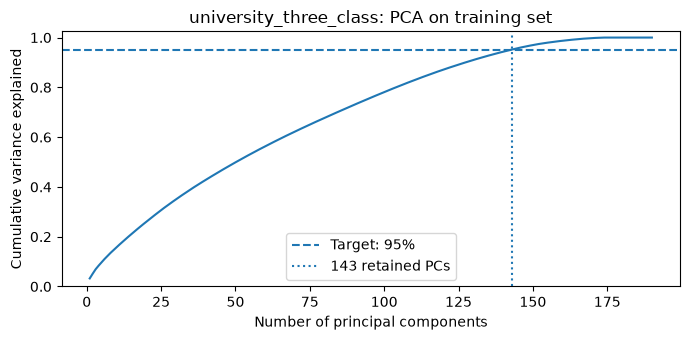

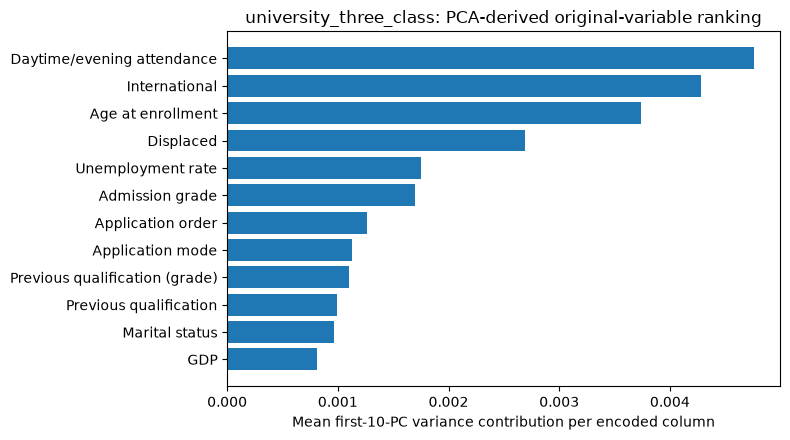

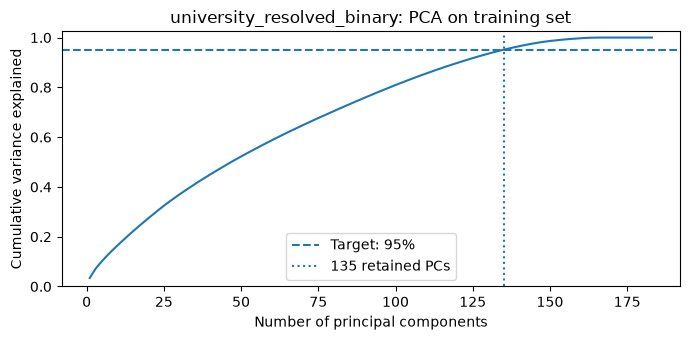

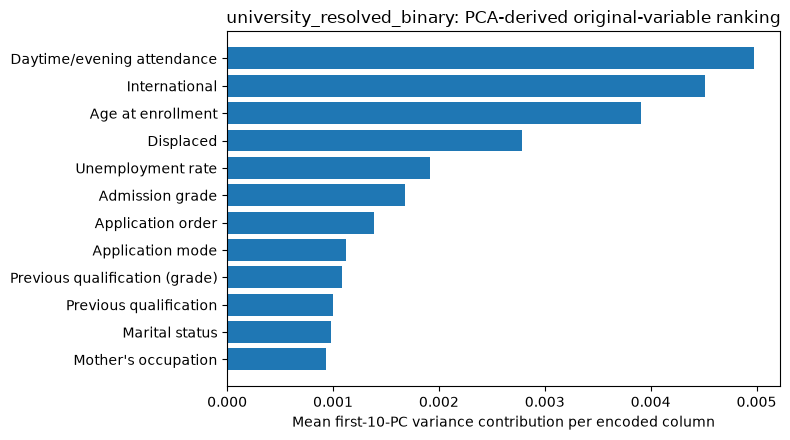

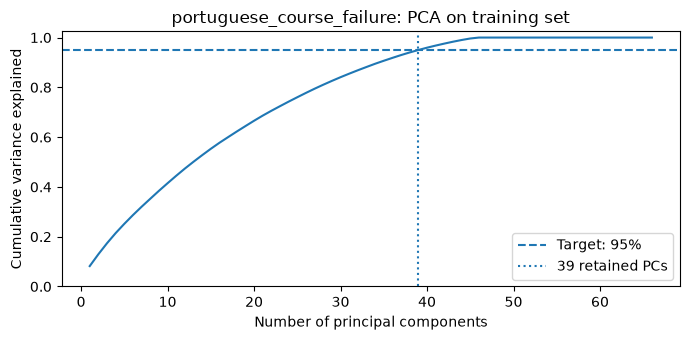

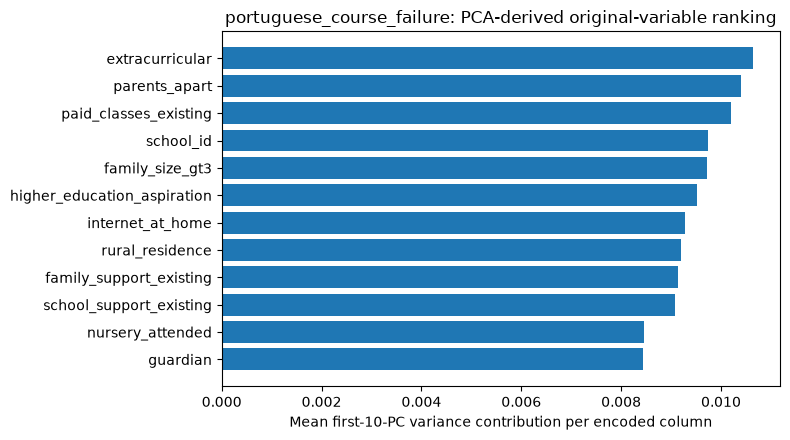

In [41]:
for task_name, s in pca_studies.items():
    # Full singular spectrum estimated on the training examples only, for visualization.
    full_pca = PCA(svd_solver='full').fit(s['scaled_x']['train'])
    cumulative = np.cumsum(full_pca.explained_variance_ratio_)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(np.arange(1, len(cumulative)+1), cumulative)
    ax.axhline(PCA_VARIANCE_TARGET, linestyle='--', label='Target: 95%')
    ax.axvline(s['pca_dim'], linestyle=':', label=f'{s["pca_dim"]} retained PCs')
    ax.set(xlabel='Number of principal components', ylabel='Cumulative variance explained',
           title=f'{task_name}: PCA on training set', ylim=(0, 1.025))
    ax.legend(); plt.tight_layout(); plt.show()

    top = s['ranked_fields'].head(12).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(top['source_feature'], top['pca_variance_contribution'])
    ax.set(xlabel='Mean first-10-PC variance contribution per encoded column',
           title=f'{task_name}: PCA-derived original-variable ranking')
    plt.tight_layout(); plt.show()

    # Save PC loadings; each PC is a feature for the direct-PCA models.
    pd.DataFrame(s['pca'].components_,
                 index=[f'PC{i+1}' for i in range(s['pca_dim'])],
                 columns=s['original']['preprocessor'].get_feature_names_out()
                ).to_csv(OUTPUT_DIR/f'{task_name}_pca_component_loadings.csv',index_label='principal_component')

## Train machine-learning and neural-network models using the PCA features

For each original task, we train **prior, logistic regression, random forest, gradient boosting and the PyTorch neural network** on the principal components. We also repeat the same models after restricting the input to the PCA-ranked *original* fields. All fits share the original labels, seed, splits, scoring and validation-based selection rules. Training the NN on PCs tests whether compact linear representations improve generalization; it is **not equivalent to selecting the most predictive raw features**.

In [42]:
def fit_representation_models(exp, feature_matrices, representation, *, preprocessing=None):
    """Run the original model zoo on fixed, train-only-fitted representations."""
    y = exp['y']
    classes = len(exp['labels'])
    models = model_factories()
    predictions = {}
    for model_name, model in models.items():
        model.fit(feature_matrices['train'], y['train'])
        if hasattr(model, 'classes_'):
            assert np.array_equal(model.classes_, np.arange(classes))
        predictions[model_name] = {
            part: model.predict_proba(feature_matrices[part]) for part in ('validation', 'test')
        }

    nn_model, history, best_epoch = fit_neural_net(
        feature_matrices['train'], y['train'], feature_matrices['validation'],
        y['validation'], classes)
    net_name = 'Neural network (PyTorch)'
    models[net_name] = nn_model
    predictions[net_name] = {
        part: nn_proba(nn_model, feature_matrices[part]) for part in ('validation', 'test')
    }
    report = pd.DataFrame([
        {'model': model_name, 'split': part, 'representation': representation,
         'task': exp['name'], **scores(y[part], proba[part])}
        for model_name, proba in predictions.items()
        for part in ('validation', 'test')
    ])
    validation_rank = report.query("split == 'validation'").sort_values(
        ['positive_pr_auc', 'positive_brier'], ascending=[False, True])
    winner = str(validation_rank.iloc[0]['model'])
    return {'report': report, 'winner': winner, 'models': models,
            'predictions': predictions, 'history': history,
            'nn_best_epoch': best_epoch,
            'x': feature_matrices, 'preprocessing': preprocessing}

for task_name, s in pca_studies.items():
    exp = s['original']
    s['pca_models'] = fit_representation_models(exp, s['pca_x'], 'PCA components (95%)')

    selected_cat = [c for c in s['categorical'] if c in s['selected_fields']]
    selected_num = [n for n in s['numeric'] if n in s['selected_fields']]
    selected_features = selected_cat + selected_num
    assert set(selected_features) == set(s['selected_fields'])
    selected_prep = make_preprocessor(selected_cat, selected_num)
    selected_x = {'train': np.asarray(
        selected_prep.fit_transform(exp['parts']['train'][selected_features]), dtype=np.float32)}
    for part in ('validation', 'test'):
        selected_x[part] = np.asarray(
            selected_prep.transform(exp['parts'][part][selected_features]), dtype=np.float32)
    assert all(np.isfinite(z).all() for z in selected_x.values())
    s['selected_fields_models'] = fit_representation_models(
        exp, selected_x, 'PCA-ranked original fields (60%)', preprocessing=selected_prep)

    print(f'\n{task_name}: PCA components winner: {s["pca_models"]["winner"]}; '
          f'PCA-ranked source fields winner: {s["selected_fields_models"]["winner"]}')
    display(pd.concat([s['pca_models']['report'],s['selected_fields_models']['report']])
            .query("split == 'validation'")[['representation','model','positive_pr_auc',
                  'positive_roc_auc','macro_f1','positive_brier']].round(3))
    pd.concat([s['pca_models']['report'],s['selected_fields_models']['report']]).to_csv(
        OUTPUT_DIR / f'{task_name}_pca_model_metrics.csv', index=False)


university_three_class: PCA components winner: Neural network (PyTorch); PCA-ranked source fields winner: Random forest


,representation,model,positive_pr_auc,positive_roc_auc,macro_f1,positive_brier
0,PCA components (95%),Prior / majority,0.319,0.500,0.221,0.217
2,PCA components (95%),Logistic regression,0.551,0.725,0.467,0.189
4,PCA components (95%),Random forest,0.526,0.721,0.410,0.191
6,PCA components (95%),Gradient boosting,0.532,0.705,0.447,0.198
8,PCA components (95%),Neural network (PyTorch),0.575,0.725,0.410,0.186
0,PCA-ranked original fields (60%),Prior / majority,0.319,0.500,0.221,0.217
2,PCA-ranked original fields (60%),Logistic regression,0.512,0.681,0.388,0.197
4,PCA-ranked original fields (60%),Random forest,0.545,0.694,0.402,0.192
6,PCA-ranked original fields (60%),Gradient boosting,0.518,0.666,0.419,0.200
8,PCA-ranked original fields (60%),Neural network (PyTorch),0.523,0.694,0.386,0.195



university_resolved_binary: PCA components winner: Logistic regression; PCA-ranked source fields winner: Random forest


,representation,model,positive_pr_auc,positive_roc_auc,macro_f1,positive_brier
0,PCA components (95%),Prior / majority,0.391,0.500,0.378,0.238
2,PCA components (95%),Logistic regression,0.664,0.747,0.677,0.197
4,PCA components (95%),Random forest,0.637,0.744,0.666,0.199
6,PCA components (95%),Gradient boosting,0.638,0.730,0.673,0.203
8,PCA components (95%),Neural network (PyTorch),0.657,0.750,0.688,0.195
0,PCA-ranked original fields (60%),Prior / majority,0.391,0.500,0.378,0.238
2,PCA-ranked original fields (60%),Logistic regression,0.607,0.707,0.623,0.209
4,PCA-ranked original fields (60%),Random forest,0.636,0.723,0.643,0.202
6,PCA-ranked original fields (60%),Gradient boosting,0.615,0.698,0.631,0.210
8,PCA-ranked original fields (60%),Neural network (PyTorch),0.626,0.721,0.645,0.205



portuguese_course_failure: PCA components winner: Logistic regression; PCA-ranked source fields winner: Logistic regression


,representation,model,positive_pr_auc,positive_roc_auc,macro_f1,positive_brier
0,PCA components (95%),Prior / majority,0.096,0.500,0.475,0.092
2,PCA components (95%),Logistic regression,0.376,0.773,0.601,0.095
4,PCA components (95%),Random forest,0.305,0.803,0.546,0.084
6,PCA components (95%),Gradient boosting,0.342,0.794,0.620,0.091
8,PCA components (95%),Neural network (PyTorch),0.312,0.768,0.610,0.082
0,PCA-ranked original fields (60%),Prior / majority,0.096,0.500,0.475,0.092
2,PCA-ranked original fields (60%),Logistic regression,0.396,0.898,0.668,0.086
4,PCA-ranked original fields (60%),Random forest,0.395,0.893,0.657,0.077
6,PCA-ranked original fields (60%),Gradient boosting,0.377,0.883,0.703,0.110
8,PCA-ranked original fields (60%),Neural network (PyTorch),0.354,0.891,0.610,0.075


## Did PCA improve held-out metrics? Compare with the original baseline

**Primary comparison:** validation-selected winner for each representation, scored once on the same held-out test examples. **Additional comparison:** each particular model (notably the neural network) with and without PCA. Positive differences in PR-AUC, ROC-AUC, macro-F1 and recall are improvements; **negative differences in Brier or log loss** are improvements. Highlight that small differences on a limited test cohort might be noise, not reliable evidence of an advantage. We do not select a new winner based on test metrics.

In [43]:
METRICS = ['positive_pr_auc', 'positive_roc_auc', 'macro_f1',
           'positive_recall', 'positive_brier', 'log_loss', 'recall_at_top_10pct']
all_pca_reports = []
selected_comparison = []
for task_name, s in pca_studies.items():
    orig = s['original']
    original_report = orig['report'].copy()
    original_report['task'] = task_name
    original_report['representation'] = 'Original encoded features'
    all_pca_reports.extend([original_report,
                            s['pca_models']['report'], s['selected_fields_models']['report']])

    for representation, report, winner in [
        ('Original encoded features', original_report, orig['winner']),
        ('PCA components (95%)', s['pca_models']['report'], s['pca_models']['winner']),
        ('PCA-ranked original fields (60%)', s['selected_fields_models']['report'],
         s['selected_fields_models']['winner']),
    ]:
        row = report.loc[(report['split']=='test') & (report['model']==winner)].iloc[0]
        selected_comparison.append({'task': task_name, 'representation': representation,
                                    'selected_using_validation': winner,
                                    'test_n': len(orig['y']['test']),
                                    **{metric: row[metric] for metric in METRICS}})

selected_comparison = pd.DataFrame(selected_comparison)
selected_comparison.to_csv(OUTPUT_DIR/'pca_vs_original_selected_models.csv',index=False)
all_representation_metrics = pd.concat(all_pca_reports, ignore_index=True)
all_representation_metrics.to_csv(OUTPUT_DIR/'pca_vs_original_all_models.csv',index=False)

# Report improvements against the original task's validation-selected model.
original_rows = selected_comparison.query("representation == 'Original encoded features'")
improvement_rows=[]
for _, r in selected_comparison.iterrows():
    ref=original_rows.loc[original_rows.task.eq(r['task'])].iloc[0]
    improvement_rows.append({
        'task':r['task'], 'representation':r['representation'],
        'delta_PR_AUC':r['positive_pr_auc']-ref['positive_pr_auc'],
        'delta_ROC_AUC':r['positive_roc_auc']-ref['positive_roc_auc'],
        'delta_macro_F1':r['macro_f1']-ref['macro_f1'],
        'delta_Brier':r['positive_brier']-ref['positive_brier'],
    })
improvements=pd.DataFrame(improvement_rows)
improvements.to_csv(OUTPUT_DIR/'pca_vs_original_selected_deltas.csv', index=False)
print('Validation-selected model for each input representation — HELD-OUT TEST metrics:')
display(selected_comparison.round(4))
print('Difference from the corresponding original-representation selected baseline:')
display(improvements.round(4))

Validation-selected model for each input representation — HELD-OUT TEST metrics:


,task,representation,selected_using_validation,test_n,positive_pr_auc,positive_roc_auc,macro_f1,positive_recall,positive_brier,log_loss,recall_at_top_10pct
0,university_three_class,Original encoded features,Random forest,908,0.6056,0.7696,0.4110,0.4896,0.1780,0.8944,0.2083
1,university_three_class,PCA components (95%),Neural network (PyTorch),908,0.5422,0.7295,0.3968,0.4583,0.1870,0.9245,0.2083
2,university_three_class,PCA-ranked original fields (60%),Random forest,908,0.5632,0.7224,0.4017,0.4618,0.1857,0.9420,0.2222
3,university_resolved_binary,Original encoded features,Random forest,744,0.7168,0.7955,0.6904,0.5139,0.1820,0.5452,0.2188
4,university_resolved_binary,PCA components (95%),Logistic regression,744,0.6795,0.7672,0.6758,0.4861,0.1882,0.5786,0.2083
5,university_resolved_binary,PCA-ranked original fields (60%),Random forest,744,0.6433,0.7330,0.6800,0.4896,0.1990,0.5845,0.1910
6,portuguese_course_failure,Original encoded features,Gradient boosting,136,0.7732,0.9426,0.8311,0.6818,0.0705,0.2812,0.4545
7,portuguese_course_failure,PCA components (95%),Logistic regression,136,0.6470,0.8752,0.7470,0.5909,0.0966,0.3253,0.4091
8,portuguese_course_failure,PCA-ranked original fields (60%),Logistic regression,136,0.7405,0.9310,0.7948,0.5909,0.0750,0.2399,0.4545


Difference from the corresponding original-representation selected baseline:


,task,representation,delta_PR_AUC,delta_ROC_AUC,delta_macro_F1,delta_Brier
0,university_three_class,Original encoded features,0.0000,0.0000,0.0000,0.0000
1,university_three_class,PCA components (95%),-0.0634,-0.0402,-0.0142,0.0090
2,university_three_class,PCA-ranked original fields (60%),-0.0424,-0.0472,-0.0093,0.0077
3,university_resolved_binary,Original encoded features,0.0000,0.0000,0.0000,0.0000
4,university_resolved_binary,PCA components (95%),-0.0374,-0.0283,-0.0146,0.0062
5,university_resolved_binary,PCA-ranked original fields (60%),-0.0736,-0.0624,-0.0104,0.0171
6,portuguese_course_failure,Original encoded features,0.0000,0.0000,0.0000,0.0000
7,portuguese_course_failure,PCA components (95%),-0.1261,-0.0674,-0.0840,0.0261
8,portuguese_course_failure,PCA-ranked original fields (60%),-0.0327,-0.0116,-0.0362,0.0045


### Neural network: direct before-and-after PCA comparison

The comparison below holds the learning algorithm fixed (PyTorch MLP) and changes only the input representation. This directly tests the request: **does feeding principal components—or the original variables ranked by PCA—to a neural network improve predictive performance?** In contrast, the previous table permits the validation-selected algorithm itself to change between input representations.

,task,representation,positive_pr_auc,positive_roc_auc,macro_f1,positive_recall,positive_brier,log_loss,recall_at_top_10pct,delta_positive_pr_auc,delta_positive_roc_auc,delta_macro_f1,delta_positive_recall,delta_positive_brier,delta_log_loss,delta_recall_at_top_10pct
9,university_three_class,Original encoded features,0.6139,0.7671,0.4314,0.5972,0.1742,0.8837,0.2361,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
19,university_three_class,PCA components (95%),0.5422,0.7295,0.3968,0.4583,0.1870,0.9245,0.2083,-0.0718,-0.0377,-0.0346,-0.1389,0.0127,0.0408,-0.0278
29,university_three_class,PCA-ranked original fields (60%),0.5673,0.7176,0.4039,0.4583,0.1859,0.9459,0.2118,-0.0466,-0.0495,-0.0275,-0.1389,0.0116,0.0622,-0.0243
39,university_resolved_binary,Original encoded features,0.6848,0.7781,0.6895,0.5451,0.1847,0.5485,0.2049,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
49,university_resolved_binary,PCA components (95%),0.6579,0.7624,0.6554,0.4549,0.1909,0.5618,0.1944,-0.0269,-0.0157,-0.0341,-0.0903,0.0063,0.0133,-0.0104
59,university_resolved_binary,PCA-ranked original fields (60%),0.6287,0.7168,0.6563,0.4479,0.2030,0.5956,0.1910,-0.0561,-0.0613,-0.0332,-0.0972,0.0184,0.0471,-0.0139
69,portuguese_course_failure,Original encoded features,0.5901,0.8959,0.6628,0.2727,0.0934,0.2936,0.3636,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
79,portuguese_course_failure,PCA components (95%),0.6453,0.8636,0.6417,0.2273,0.0964,0.3138,0.5000,0.0552,-0.0323,-0.0211,-0.0455,0.0030,0.0202,0.1364
89,portuguese_course_failure,PCA-ranked original fields (60%),0.7146,0.9302,0.7213,0.4091,0.0817,0.2562,0.4545,0.1245,0.0343,0.0585,0.1364,-0.0117,-0.0374,0.0909


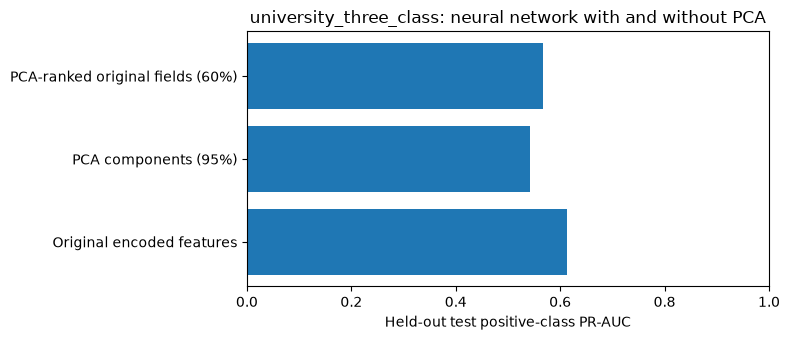

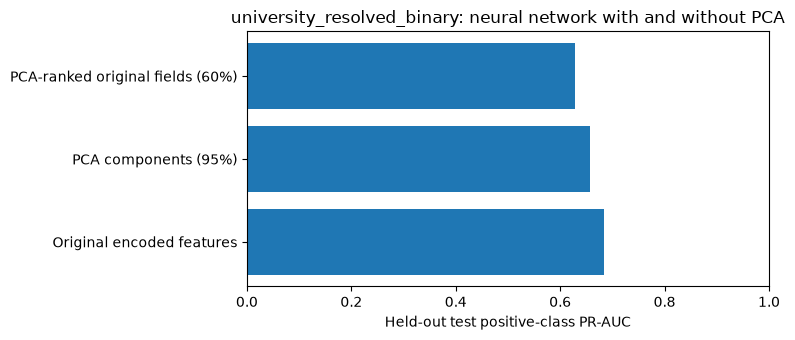

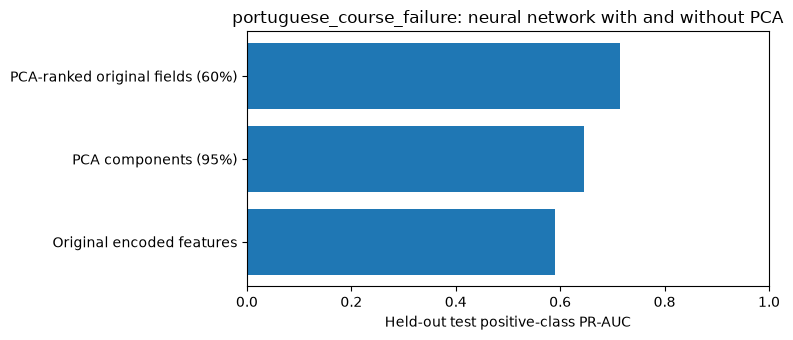

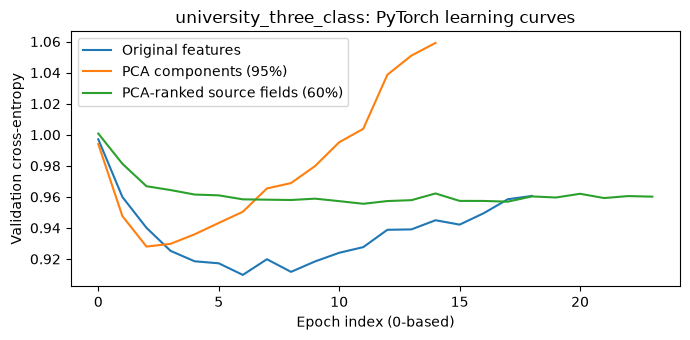

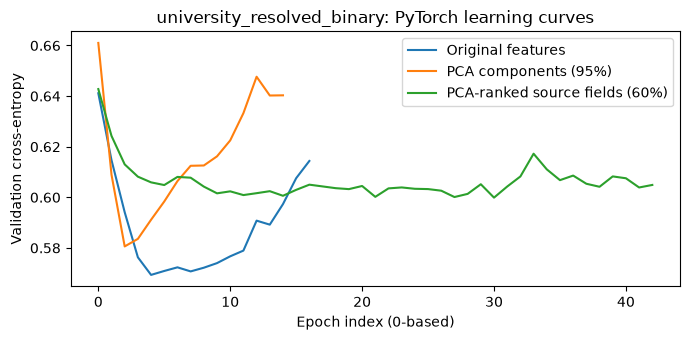

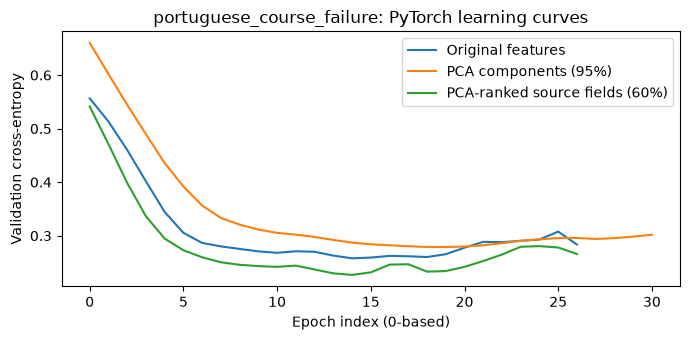

In [44]:
net_name = 'Neural network (PyTorch)'
nn_summary = all_representation_metrics.loc[
    (all_representation_metrics['split']=='test') &
    (all_representation_metrics['model']==net_name),
    ['task','representation'] + METRICS
].copy()
reference_nn = nn_summary.query("representation == 'Original encoded features'").set_index('task')
for metric in METRICS:
    nn_summary[f'delta_{metric}'] = nn_summary.apply(
        lambda row: row[metric]-reference_nn.loc[row['task'], metric], axis=1)
nn_summary.to_csv(OUTPUT_DIR/'pca_neural_network_comparison.csv', index=False)
display(nn_summary.round(4))

for task_name, frame in nn_summary.groupby('task', sort=False):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.barh(frame['representation'], frame['positive_pr_auc'])
    ax.set(xlabel='Held-out test positive-class PR-AUC',
           title=f'{task_name}: neural network with and without PCA', xlim=(0,1))
    plt.tight_layout(); plt.show()

# Show the neural-network validation training curves for each new representation.
for task_name, s in pca_studies.items():
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(s['original']['history']['nn_val_loss'], label='Original features')
    ax.plot(s['pca_models']['history'], label='PCA components (95%)')
    ax.plot(s['selected_fields_models']['history'], label='PCA-ranked source fields (60%)')
    ax.set(xlabel='Epoch index (0-based)', ylabel='Validation cross-entropy',
           title=f'{task_name}: PyTorch learning curves')
    ax.legend();plt.tight_layout();plt.show()

## Interpretation and reproducibility

- Check `pca_dimension_summary.csv` for the actual number of retained components; 95% explained training variance does *not* imply 95% predictive information retained.
- Check `*_pca_source_feature_ranking.csv` to inspect which *original* variables contribute most to the first ten dominant PCA directions; this is **unsupervised variance-based ranking**, not supervised feature importance or a causal effect estimate.
- Compare `pca_neural_network_comparison.csv` for neural-network changes alone and `pca_vs_original_selected_models.csv` for the winner in each representation.
- If PCA helps on the test set, treat it as a preliminary finding for that task and sampling split. If it hurts, **keep the original encoding** as the better empirical representation and report the negative result. Do not repeatedly change variance targets or variable counts based on the test set.
- All original sections remain: data audit, university three-class, university resolved-case binary, Portuguese school failure, neural-network training curves, test confusion/PR/calibration plots, subgroup descriptions, synthetic hazard diagnostic and original baseline model comparison.
- No intervention outcomes or school-withdrawal labels are supplied here: PCA cannot establish real child-dropout reduction or mentor effectiveness.